In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

Matplotlib is building the font cache; this may take a moment.


In [5]:
df = pd.read_csv("../data/processed/SeoulBikeData_processed.csv")

1.la distribution de la cible:

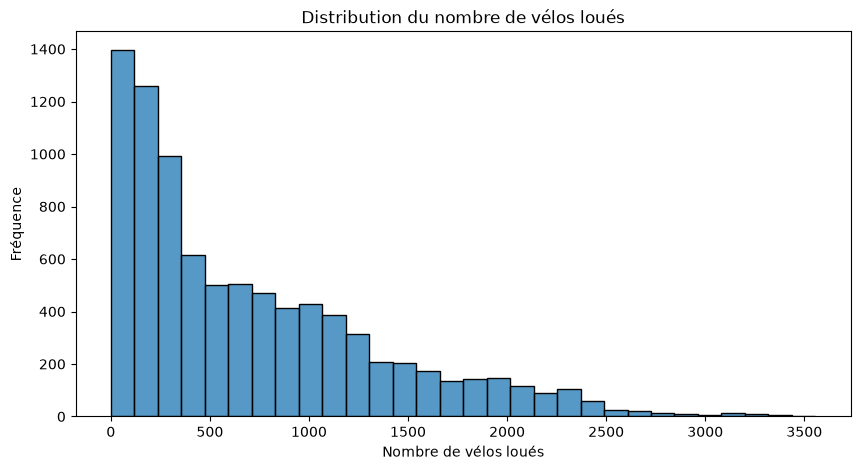

In [23]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df , x="Rented Bike Count", bins=30)
plt.title("Distribution du nombre de vélos loués")
plt.xlabel("Nombre de vélos loués")
plt.ylabel("Fréquence")
plt.savefig("../reports/figures/01_distribution_cible.png")
plt.show()

### Observation
La distribution montre que le nombre de vélos loués varie d'une heure à une autre. Certaines valeurs de location sont plus fréquentes que d'autres. On observe également des heures avec une demande élevée.

### Limite
Ce graphique présente la répartition générale des locations, mais il ne permet pas d'identifier les heures ou les saisons pendant lesquelles la demande est élevée.


2.courbe chronologique:

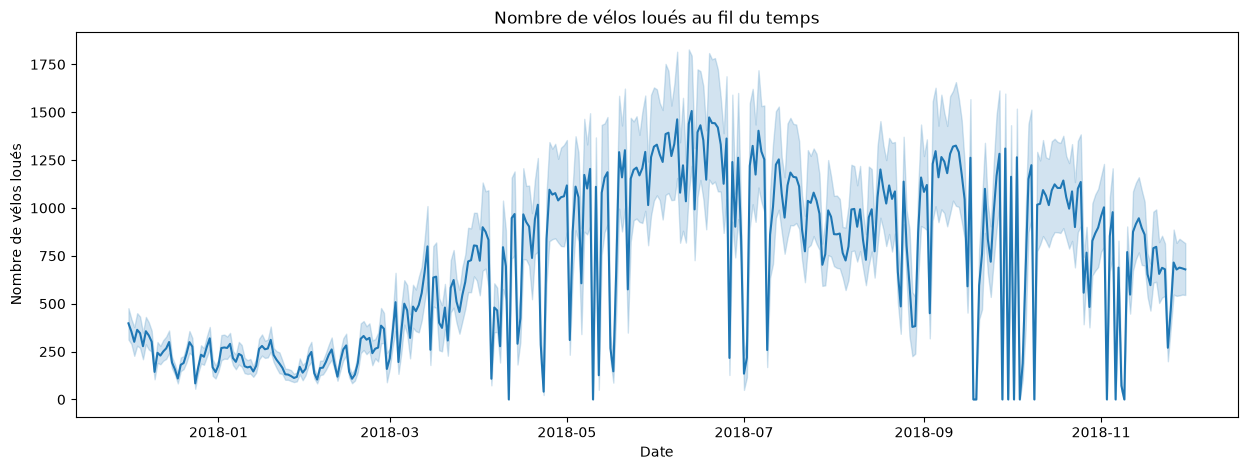

In [68]:
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
plt.figure(figsize=(15,5))
sns.lineplot(data=df , x="Date",y="Rented Bike Count")
plt.title("Nombre de vélos loués au fil du temps")
plt.xlabel("Date")
plt.ylabel("Nombre de vélos loués")
plt.savefig("../reports/figures/02_Courbe_chronologique.png")
plt.show()

### Observation
La demande de vélos varie au cours de l'année. On observe des périodes avec une demande plus élevée et d'autres avec une demande plus faible.

### Limite
Cette courbe montre l'évolution de la demande dans le temps, mais elle ne permet pas à elle seule d'expliquer les raisons de ces variations.

3.profil horaire:

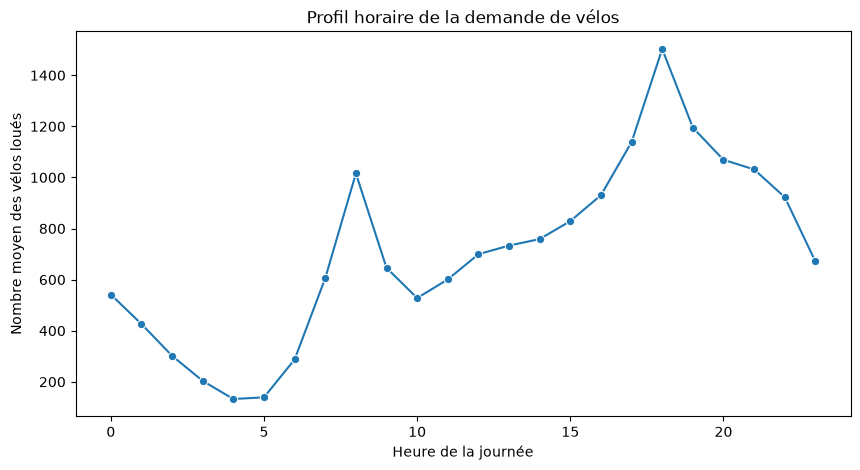

In [37]:
profil_horaire=df.groupby("Hour")["Rented Bike Count"].mean().reset_index()
plt.figure(figsize=(10,5))
sns.lineplot(data=profil_horaire ,x="Hour" , y= "Rented Bike Count" , marker="o")
plt.title("Profil horaire de la demande de vélos")
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre moyen des vélos loués")
plt.savefig("../reports/figures/03-profil_horaire.png")
plt.show()

### Observation
La moyenne des locations varie selon l'heure de la journée. Certaines heures présentent une demande plus importante que d'autres.

### Limite
Ce graphique présente une moyenne pour chaque heure, mais il ne montre pas les variations entre les différents jours.

4.profil par saison:

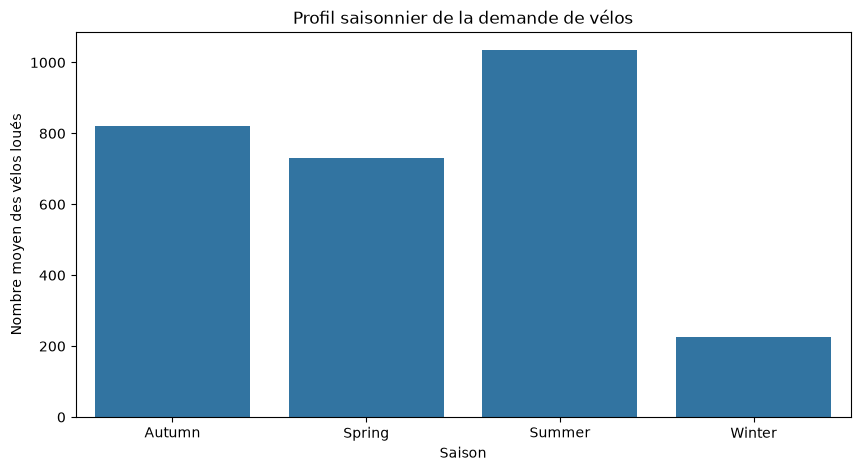

In [48]:
profile_saison=df.groupby("Seasons")["Rented Bike Count"].mean().reset_index()
plt.figure(figsize=(10,5))
sns.barplot(data=profile_saison , x="Seasons",y="Rented Bike Count")
plt.title("Profil saisonnier de la demande de vélos")
plt.xlabel("Saison")
plt.ylabel("Nombre moyen des vélos loués")
plt.savefig("../reports/figures/03-profil_par_saison.png")
plt.show()


### Observation
La demande moyenne de vélos présente des différences selon les saisons. Certaines saisons enregistrent une demande plus élevée que d'autres.

### Limite
Ce graphique compare les moyennes saisonnières, mais il ne permet pas d'expliquer précisément les facteurs responsables de ces différences.

5. demande/jour férié:

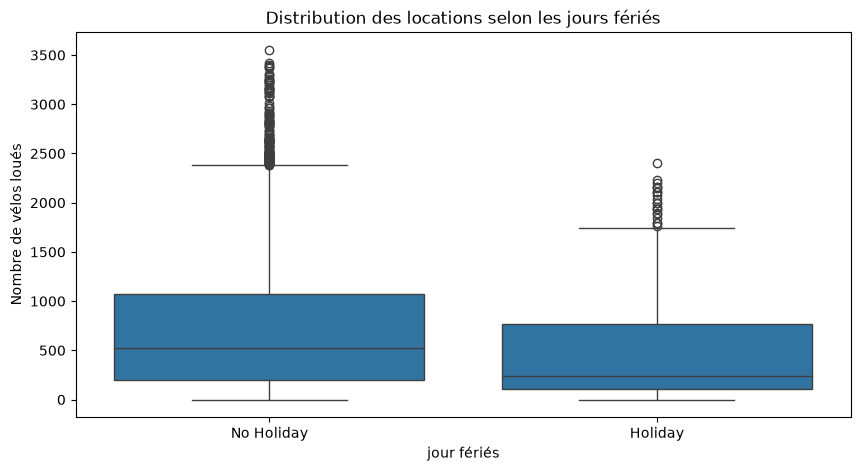

In [54]:
plt.figure(figsize=(10,5))

sns.boxplot(data= df, x="Holiday" , y ="Rented Bike Count")
plt.title("Distribution des locations selon les jours fériés")
plt.xlabel("jour fériés")
plt.ylabel("Nombre de vélos loués")
plt.savefig("../reports/figures/04-profil_par_jour_ferie.png")
plt.show()

### Observation
On observe une différence dans la distribution du nombre de vélos loués entre les jours fériés et les jours non fériés. La médiane des locations est plus élevée pendant les jours non fériés.

### Limite
Ce graphique montre une différence entre les deux catégories, mais il ne permet pas de prouver que le statut de jour férié est la cause de cette différence.

6. demande/précipitations:

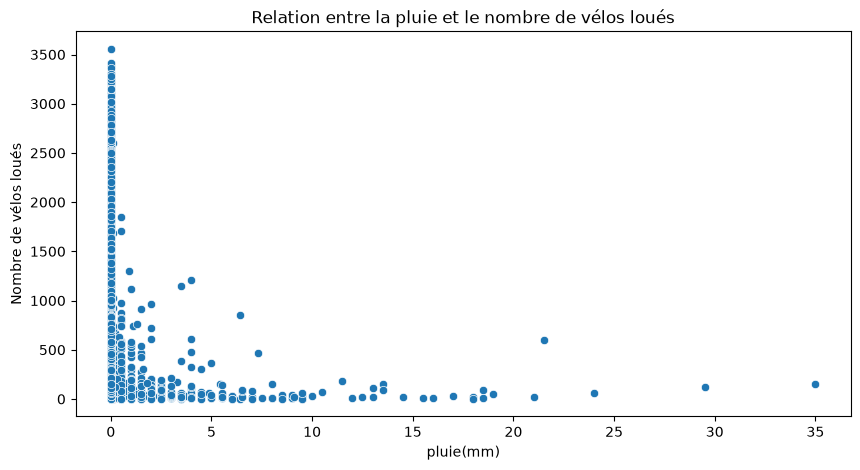

In [55]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df , x="Rainfall(mm)", y="Rented Bike Count")
plt.title("Relation entre la pluie et le nombre de vélos loués")
plt.xlabel("pluie(mm)")
plt.ylabel("Nombre de vélos loués")
plt.savefig("../reports/figures/05-relation_pluie_locations.png")
plt.show()

### Observation
On observe une relation entre les précipitations et le nombre de vélos loués. Lorsque les précipitations augmentent, la demande semble généralement diminuer.

### Limite
Ce graphique montre une corrélation éventuelle entre les précipitations et les locations, mais il ne prouve pas que la pluie est la cause de la diminution de la demande. D'autres facteurs, comme la température ou l'heure, peuvent également intervenir.

7.Demande de vélos selon le fonctionnement du service:

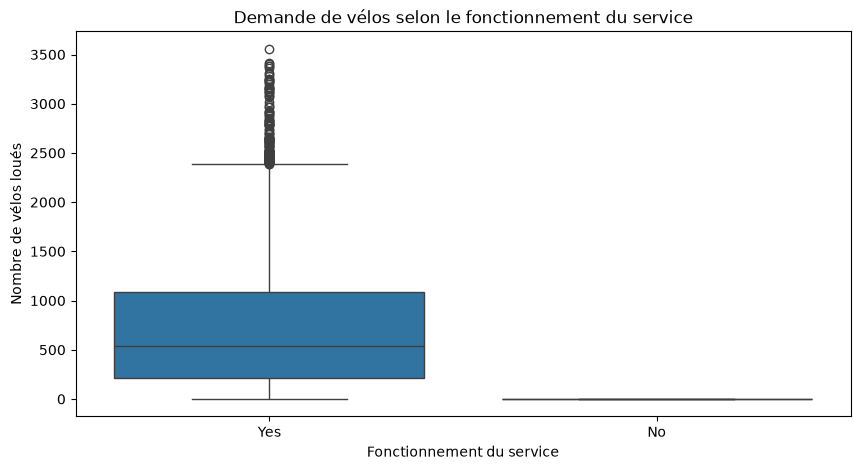

In [59]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Functioning Day", y="Rented Bike Count")
plt.title("Demande de vélos selon le fonctionnement du service")
plt.xlabel("Fonctionnement du service")
plt.ylabel("Nombre de vélos loués")
plt.savefig("../reports/figures/07_fonctionnement_service.png")
plt.show()

### Observation
On observe une différence importante entre les heures où le service fonctionne et celles où il ne fonctionne pas. Lorsque le service fonctionne, le nombre de locations varie. Lorsque le service ne fonctionne pas, le nombre de locations est généralement nul.

### Limite
Les heures où le service ne fonctionne pas ne représentent pas une demande réellement faible. L'absence de locations peut simplement s'expliquer par la fermeture du service.

8. la moyenne des locations pour chaque heure:

In [ ]:
moyenne_horaire = df.groupby("Hour")["Rented Bike Count"].mean()
print(moyenne_horaire) 

Hour
0      541.460274
1      426.183562
2      301.630137
3      203.331507
4      132.591781
5      139.082192
6      287.564384
7      606.005479
8     1015.701370
9      645.983562
10     527.821918
11     600.852055
12     699.441096
13     733.246575
14     758.824658
15     829.186301
16     930.621918
17    1138.509589
18    1502.926027
19    1195.147945
20    1068.964384
21    1031.449315
22     922.797260
23     671.126027
Name: Rented Bike Count, dtype: float64


9. Comparaison des distributions en semaine et pendant les jours fériés:

C:\Users\soumi\AppData\Local\Temp\ipykernel_15936\192376843.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["jour_semaine"]=df["Date"].dt.dayofweek


Text(0, 0.5, 'Nombre de vélos loués')

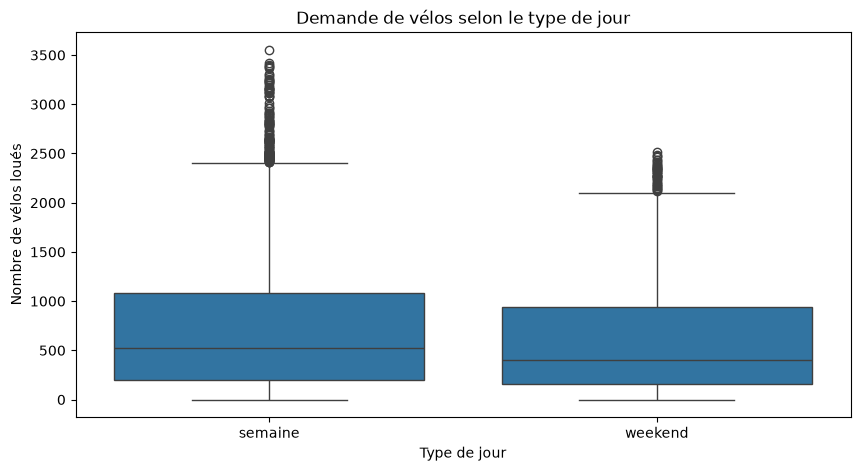

In [66]:
df["jour_semaine"]=df["Date"].dt.dayofweek
df["Type_jour"]=df["jour_semaine"].apply(lambda x: "semaine" if x<=5 else "weekend")

plt.figure(figsize=(10,5))
sns.boxplot(data=df , x="Type_jour" , y="Rented Bike Count")
plt.title("Demande de vélos selon le type de jour")
plt.xlabel("Type de jour")
plt.ylabel("Nombre de vélos loués") 
